In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "DATA" / "PROCESSED"
OUTPUT_DIR = DATA_PROCESSED_DIR / "BOWLING"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data:", DATA_PROCESSED_DIR)
print("Bowling output directory:", OUTPUT_DIR)

Project root: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE
Processed data: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED
Bowling output directory: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\BOWLING


In [3]:
deliveries_path = DATA_PROCESSED_DIR / "deliveries.csv"
matches_path = DATA_PROCESSED_DIR / "matches.csv"

if not deliveries_path.exists():
    raise FileNotFoundError(
        f"Missing {deliveries_path}. Run Notebook 02 first."
    )

if not matches_path.exists():
    raise FileNotFoundError(
        f"Missing {matches_path}. Run Notebook 02 first."
    )

deliveries_df = pd.read_csv(deliveries_path, low_memory=False)
matches_df = pd.read_csv(matches_path, low_memory=False)

print("Deliveries shape:", deliveries_df.shape)
print("Matches shape:", matches_df.shape)

display(deliveries_df.head())
display(matches_df.head())

Deliveries shape: (295732, 27)
Matches shape: (1243, 26)


,match_id,season,start_date,venue,innings,ball,actual_delivery,batting_team,bowling_team,striker,...,legbyes,penalty,non_boundary,wicket_type,player_dismissed,other_wicket_type,other_player_dismissed,fielder_1,fielder_2,fielder_3
0,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.1,0.1,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.2,0.2,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.3,0.3,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.4,0.4,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1082591,2017.0,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.5,0.5,Sunrisers Hyderabad,Royal Challengers Bangalore,DA Warner,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,match_id,season,date,event,match_type,match_number,gender,team_1,team_2,venue,...,winner_wickets,overs,balls_per_over,target_runs,target_overs,team_1_players,team_2_players,umpires,match_referee,info_version
0,1082591,2017.0,2017-04-05,Indian Premier League,T20,1.0,male,Sunrisers Hyderabad,Royal Challengers Bangalore,"Rajiv Gandhi International Stadium, Uppal",...,NaN,20,6,208.0,20.0,DA Warner | S Dhawan | MC Henriques | Yuvraj S...,CH Gayle | Mandeep Singh | TM Head | KM Jadhav...,AY Dandekar | NJ Llong,J Srinath,2.3.0
1,1082592,2017.0,2017-04-06,Indian Premier League,T20,2.0,male,Rising Pune Supergiant,Mumbai Indians,Maharashtra Cricket Association Stadium,...,7.0,20,6,185.0,20.0,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,PA Patel | JC Buttler | RG Sharma | N Rana | A...,A Nand Kishore | S Ravi,M Nayyar,2.3.0
2,1082593,2017.0,2017-04-07,Indian Premier League,T20,3.0,male,Gujarat Lions,Kolkata Knight Riders,Saurashtra Cricket Association Stadium,...,10.0,20,6,184.0,20.0,JJ Roy | BB McCullum | SK Raina | AJ Finch | K...,G Gambhir | CA Lynn | RV Uthappa | MK Pandey |...,Nitin Menon | CK Nandan,V Narayan Kutty,2.3.0
3,1082594,2017.0,2017-04-08,Indian Premier League,T20,4.0,male,Kings XI Punjab,Rising Pune Supergiant,Holkar Cricket Stadium,...,6.0,20,6,164.0,20.0,HM Amla | M Vohra | WP Saha | AR Patel | GJ Ma...,AM Rahane | MA Agarwal | SPD Smith | BA Stokes...,AK Chaudhary | C Shamshuddin,Chinmay Sharma,2.3.0
4,1082595,2017.0,2017-04-08,Indian Premier League,T20,5.0,male,Royal Challengers Bangalore,Delhi Daredevils,M.Chinnaswamy Stadium,...,NaN,20,6,158.0,20.0,CH Gayle | SR Watson | Mandeep Singh | KM Jadh...,AP Tare | SW Billings | KK Nair | SV Samson | ...,S Ravi | VK Sharma,J Srinath,2.3.0


In [4]:
required_columns = [
    "match_id",
    "season",
    "innings",
    "batting_team",
    "bowling_team",
    "bowler",
    "runs_off_bat",
    "extras",
    "wides",
    "noballs",
    "byes",
    "legbyes",
    "penalty",
    "wicket_type",
    "player_dismissed",
]

missing_columns = [
    col for col in required_columns
    if col not in deliveries_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("Required columns are available.")
print("Unique matches:", deliveries_df["match_id"].nunique())
print("Unique bowlers:", deliveries_df["bowler"].nunique())
print("Unique seasons:", deliveries_df["season"].nunique())

Required columns are available.
Unique matches: 1243
Unique bowlers: 578
Unique seasons: 16


In [5]:
bowling_df = deliveries_df.copy()

numeric_columns = [
    "innings",
    "runs_off_bat",
    "extras",
    "wides",
    "noballs",
    "byes",
    "legbyes",
    "penalty",
]

for col in numeric_columns:
    bowling_df[col] = pd.to_numeric(
        bowling_df[col], errors="coerce"
    )

for col in [
    "runs_off_bat",
    "extras",
    "wides",
    "noballs",
    "byes",
    "legbyes",
    "penalty",
]:
    bowling_df[col] = bowling_df[col].fillna(0)

# Normalize blank bowler names.
bowling_df["bowler"] = bowling_df["bowler"].replace(
    r"^\s*$", np.nan, regex=True
)

# Team runs scored on each delivery.
bowling_df["total_runs"] = (
    bowling_df["runs_off_bat"] + bowling_df["extras"]
)

# A legal delivery is neither a wide nor a no-ball.
bowling_df["legal_ball"] = (
    bowling_df["wides"].eq(0)
    & bowling_df["noballs"].eq(0)
).astype(int)

# Runs charged to the bowler:
# batter runs + wides + no-ball extras.
# Byes, leg-byes and penalty runs are excluded.
bowling_df["runs_conceded"] = (
    bowling_df["runs_off_bat"]
    + bowling_df["wides"]
    + bowling_df["noballs"]
)

# Dot balls: legal deliveries on which no team runs were scored.
bowling_df["dot_ball"] = (
    bowling_df["legal_ball"].eq(1)
    & bowling_df["total_runs"].eq(0)
).astype(int)

print("Prepared delivery records:", len(bowling_df))
print("Legal deliveries:", int(bowling_df["legal_ball"].sum()))
print("Runs charged to bowlers:", int(bowling_df["runs_conceded"].sum()))

display(
    bowling_df[
        [
            "match_id", "innings", "bowling_team", "bowler",
            "runs_off_bat", "extras", "runs_conceded",
            "legal_ball", "dot_ball"
        ]
    ].head(10)
)

Prepared delivery records: 295732
Legal deliveries: 284630
Runs charged to bowlers: 394585


,match_id,innings,bowling_team,bowler,runs_off_bat,extras,runs_conceded,legal_ball,dot_ball
0,1082591,1,Royal Challengers Bangalore,TS Mills,0,0,0.0,1,1
1,1082591,1,Royal Challengers Bangalore,TS Mills,0,0,0.0,1,1
2,1082591,1,Royal Challengers Bangalore,TS Mills,4,0,4.0,1,0
3,1082591,1,Royal Challengers Bangalore,TS Mills,0,0,0.0,1,1
4,1082591,1,Royal Challengers Bangalore,TS Mills,0,2,2.0,0,0
5,1082591,1,Royal Challengers Bangalore,TS Mills,0,0,0.0,1,1
6,1082591,1,Royal Challengers Bangalore,TS Mills,0,1,0.0,1,0
7,1082591,1,Royal Challengers Bangalore,A Choudhary,1,0,1.0,1,0
8,1082591,1,Royal Challengers Bangalore,A Choudhary,4,0,4.0,1,0
9,1082591,1,Royal Challengers Bangalore,A Choudhary,0,1,1.0,0,0


In [6]:
bowler_credited_dismissals = {
    "bowled",
    "caught",
    "caught and bowled",
    "lbw",
    "stumped",
    "hit wicket",
    "hit the ball twice",
}

wickets_df = bowling_df.dropna(
    subset=["bowler", "player_dismissed", "wicket_type"]
).copy()

wickets_df["wicket_type_normalized"] = (
    wickets_df["wicket_type"]
    .astype(str)
    .str.strip()
    .str.lower()
)

credited_wickets = wickets_df[
    wickets_df["wicket_type_normalized"].isin(
        bowler_credited_dismissals
    )
].copy()

print("All recorded dismissal rows:", len(wickets_df))
print("Dismissals credited to bowlers:", len(credited_wickets))

display(
    credited_wickets[
        ["match_id", "innings", "bowler", "player_dismissed", "wicket_type"]
    ].head(10)
)

All recorded dismissal rows: 14705
Dismissals credited to bowlers: 13482


,match_id,innings,bowler,player_dismissed,wicket_type
11,1082591,1,A Choudhary,DA Warner,caught
64,1082591,1,STR Binny,S Dhawan,caught
94,1082591,1,YS Chahal,MC Henriques,caught
116,1082591,1,TS Mills,Yuvraj Singh,bowled
160,1082591,2,Rashid Khan,Mandeep Singh,bowled
165,1082591,2,DJ Hooda,CH Gayle,caught
206,1082591,2,Rashid Khan,TM Head,caught
211,1082591,2,Bipul Sharma,Sachin Baby,caught
230,1082591,2,B Kumar,STR Binny,caught
234,1082591,2,A Nehra,SR Watson,caught


In [7]:
valid_bowling = bowling_df.dropna(
    subset=["bowler", "match_id", "innings"]
).copy()

bowler_summary = (
    valid_bowling.groupby("bowler")
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        dot_balls=("dot_ball", "sum"),
        matches=("match_id", "nunique"),
    )
    .reset_index()
)

bowler_innings = (
    valid_bowling[
        ["bowler", "match_id", "innings"]
    ]
    .drop_duplicates()
    .groupby("bowler")
    .size()
    .rename("innings_bowled")
    .reset_index()
)

wicket_summary = (
    credited_wickets.groupby("bowler")
    .size()
    .rename("wickets")
    .reset_index()
)

bowler_summary = (
    bowler_summary
    .merge(bowler_innings, on="bowler", how="left")
    .merge(wicket_summary, on="bowler", how="left")
)

bowler_summary["wickets"] = (
    bowler_summary["wickets"].fillna(0).astype(int)
)

bowler_summary["overs_equivalent"] = (
    bowler_summary["legal_balls"] / 6
)

bowler_summary["economy"] = np.where(
    bowler_summary["legal_balls"] > 0,
    bowler_summary["runs_conceded"] * 6
    / bowler_summary["legal_balls"],
    np.nan
)

bowler_summary["bowling_average"] = np.where(
    bowler_summary["wickets"] > 0,
    bowler_summary["runs_conceded"] / bowler_summary["wickets"],
    np.nan
)

bowler_summary["bowling_strike_rate"] = np.where(
    bowler_summary["wickets"] > 0,
    bowler_summary["legal_balls"] / bowler_summary["wickets"],
    np.nan
)

bowler_summary = bowler_summary.sort_values(
    "wickets", ascending=False
).reset_index(drop=True)

display(bowler_summary.head(20).round(2))

,bowler,runs_conceded,legal_balls,dot_balls,matches,innings_bowled,wickets,overs_equivalent,economy,bowling_average,bowling_strike_rate
0,YS Chahal,5417.0,4037,1319,184,184,233,672.83,8.05,23.25,17.33
1,B Kumar,5913.0,4600,1897,206,206,226,766.67,7.71,26.16,20.35
2,SP Narine,5273.0,4660,1786,200,202,209,776.67,6.79,25.23,22.30
3,PP Chawla,5108.0,3850,1325,191,191,192,641.67,7.96,26.60,20.05
4,JJ Bumrah,4469.0,3653,1458,158,162,190,608.83,7.34,23.52,19.23
5,R Ashwin,5652.0,4710,1606,217,217,187,785.00,7.20,30.22,25.19
6,DJ Bravo,4360.0,3120,998,158,158,183,520.00,8.38,23.83,17.05
7,RA Jadeja,5465.0,4254,1342,237,237,180,709.00,7.71,30.36,23.63
8,Rashid Khan,4297.0,3543,1257,153,156,179,590.50,7.28,24.01,19.79
9,A Mishra,4145.0,3371,1185,162,162,174,561.83,7.38,23.82,19.37


In [8]:
over_df = bowling_df.dropna(
    subset=["match_id", "innings", "bowler"]
).copy()

# Use actual_delivery for ordering when available; otherwise use ball.
if "actual_delivery" in over_df.columns:
    over_df["delivery_order"] = pd.to_numeric(
        over_df["actual_delivery"], errors="coerce"
    )
else:
    over_df["delivery_order"] = np.nan

over_df["fallback_order"] = pd.to_numeric(
    over_df["ball"], errors="coerce"
)

over_df["delivery_order"] = over_df["delivery_order"].fillna(
    over_df["fallback_order"]
)

over_df = over_df.sort_values(
    ["match_id", "innings", "delivery_order"],
    kind="stable"
).copy()

innings_keys = ["match_id", "innings"]

# Number of legal balls before the current delivery.
over_df["legal_balls_before"] = (
    over_df.groupby(innings_keys)["legal_ball"].cumsum()
    - over_df["legal_ball"]
)

# Six legal deliveries per over; this handles wides and no-balls.
over_df["over_number"] = (
    over_df["legal_balls_before"] // 6
).astype(int)

over_summary = (
    over_df.groupby(
        ["match_id", "innings", "over_number", "bowler"],
        dropna=False
    )
    .agg(
        legal_balls=("legal_ball", "sum"),
        team_runs=("total_runs", "sum"),
        bowler_runs=("runs_conceded", "sum")
    )
    .reset_index()
)

# Count only complete overs with no runs scored by the batting side.
over_summary["maiden"] = (
    over_summary["legal_balls"].eq(6)
    & over_summary["team_runs"].eq(0)
).astype(int)

maiden_summary = (
    over_summary.groupby("bowler")["maiden"]
    .sum()
    .rename("maidens")
    .reset_index()
)

bowler_summary = bowler_summary.drop(
    columns=["maidens"], errors="ignore"
).merge(
    maiden_summary, on="bowler", how="left"
)

bowler_summary["maidens"] = (
    bowler_summary["maidens"].fillna(0).astype(int)
)

display(
    bowler_summary.sort_values(
        ["maidens", "wickets"], ascending=False
    )[
        ["bowler", "maidens", "wickets", "economy", "matches"]
    ].head(20)
)

,bowler,maidens,wickets,economy,matches
39,P Kumar,12,90,7.728209,119
1,B Kumar,9,226,7.712609,206
15,TA Boult,9,145,8.512931,124
50,IK Pathan,8,80,7.779736,101
31,DW Steyn,7,97,6.937672,95
33,DL Chahar,7,96,8.303675,103
43,DS Kulkarni,7,86,8.306659,92
4,JJ Bumrah,6,190,7.340268,158
10,SL Malinga,6,170,7.143969,122
12,Sandeep Sharma,6,151,8.170092,142


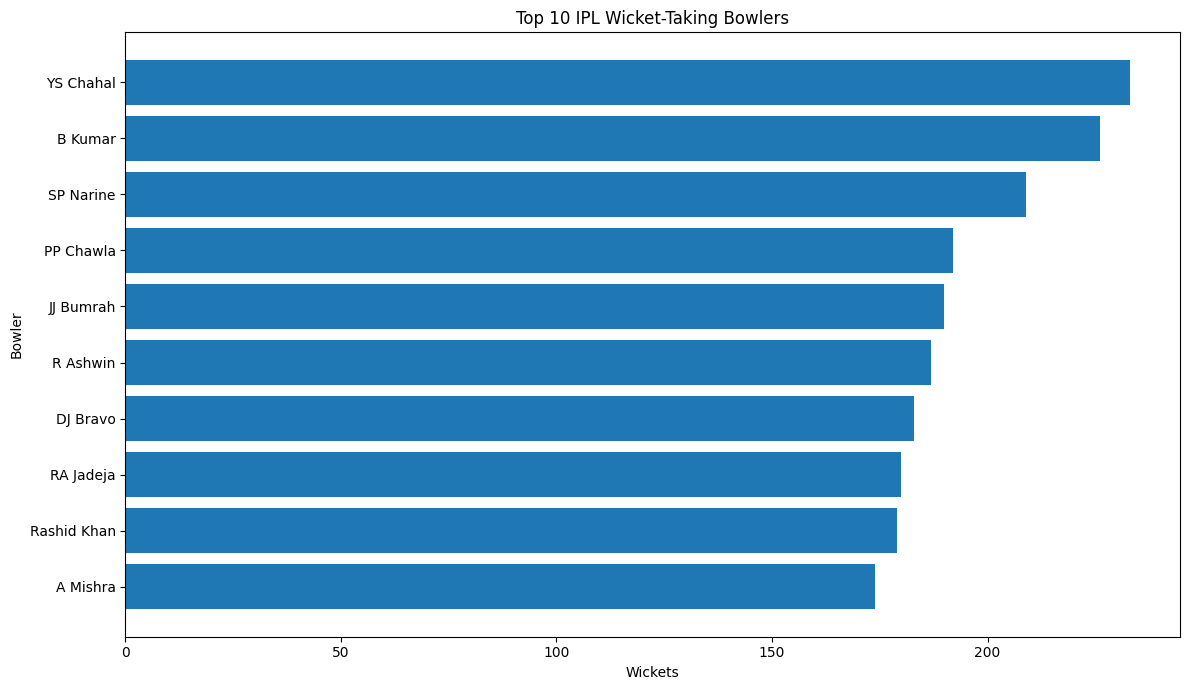

In [9]:
top_wicket_takers = (
    bowler_summary.nlargest(10, "wickets")
    .sort_values("wickets")
)

plt.figure(figsize=(12, 7))
plt.barh(
    top_wicket_takers["bowler"],
    top_wicket_takers["wickets"]
)
plt.title("Top 10 IPL Wicket-Taking Bowlers")
plt.xlabel("Wickets")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()

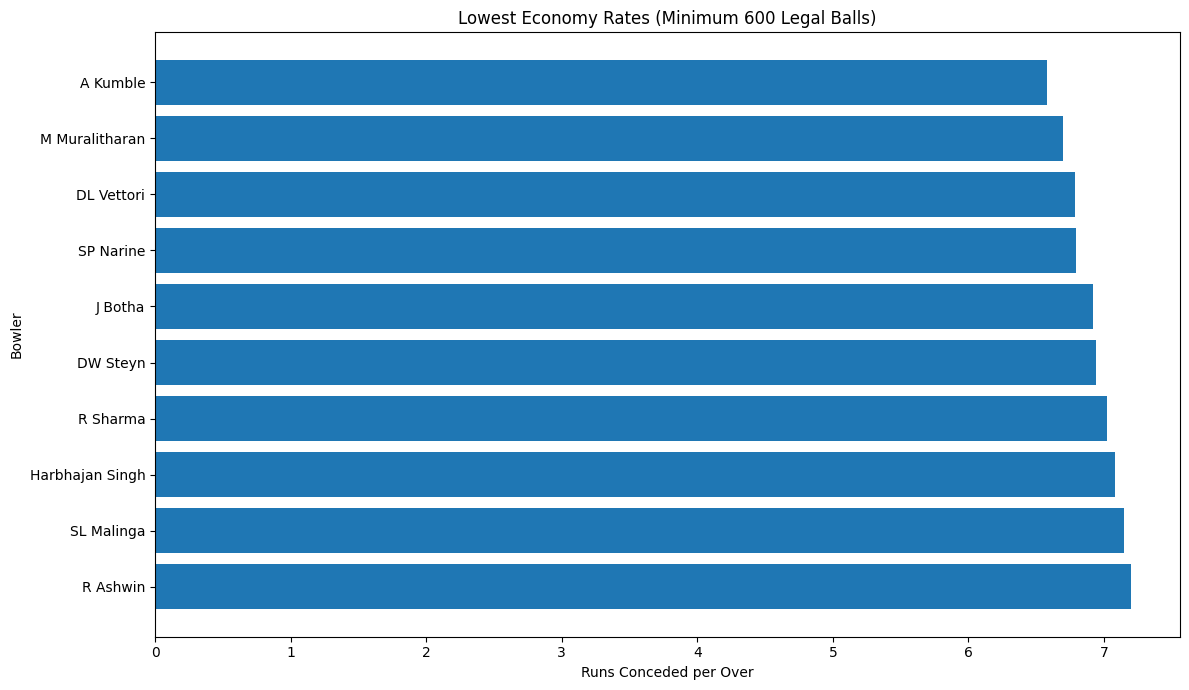

In [10]:
MIN_BALLS_FOR_ECONOMY = 600

economy_leaders = (
    bowler_summary[
        bowler_summary["legal_balls"] >= MIN_BALLS_FOR_ECONOMY
    ]
    .nsmallest(10, "economy")
    .sort_values("economy", ascending=False)
)

plt.figure(figsize=(12, 7))
plt.barh(
    economy_leaders["bowler"],
    economy_leaders["economy"]
)
plt.title(
    f"Lowest Economy Rates (Minimum {MIN_BALLS_FOR_ECONOMY} Legal Balls)"
)
plt.xlabel("Runs Conceded per Over")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()

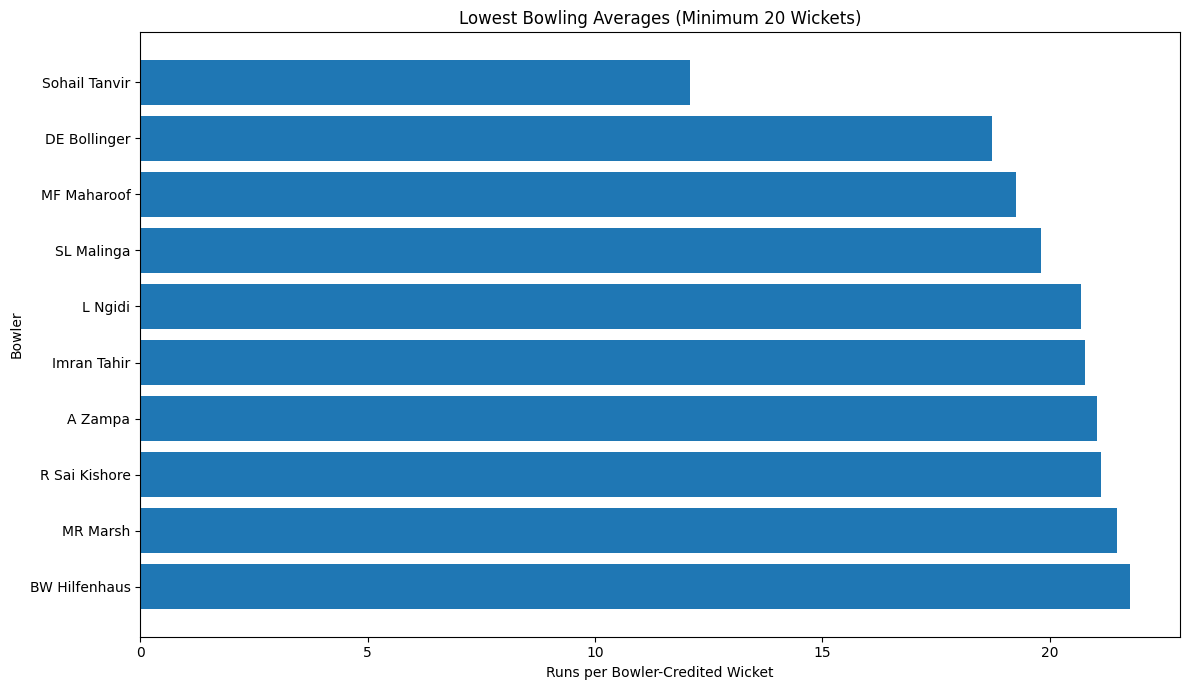

In [11]:
MIN_WICKETS_FOR_AVERAGE = 20

average_leaders = (
    bowler_summary[
        (bowler_summary["wickets"] >= MIN_WICKETS_FOR_AVERAGE)
        & bowler_summary["bowling_average"].notna()
    ]
    .nsmallest(10, "bowling_average")
    .sort_values("bowling_average", ascending=False)
)

plt.figure(figsize=(12, 7))
plt.barh(
    average_leaders["bowler"],
    average_leaders["bowling_average"]
)
plt.title(
    f"Lowest Bowling Averages (Minimum {MIN_WICKETS_FOR_AVERAGE} Wickets)"
)
plt.xlabel("Runs per Bowler-Credited Wicket")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()

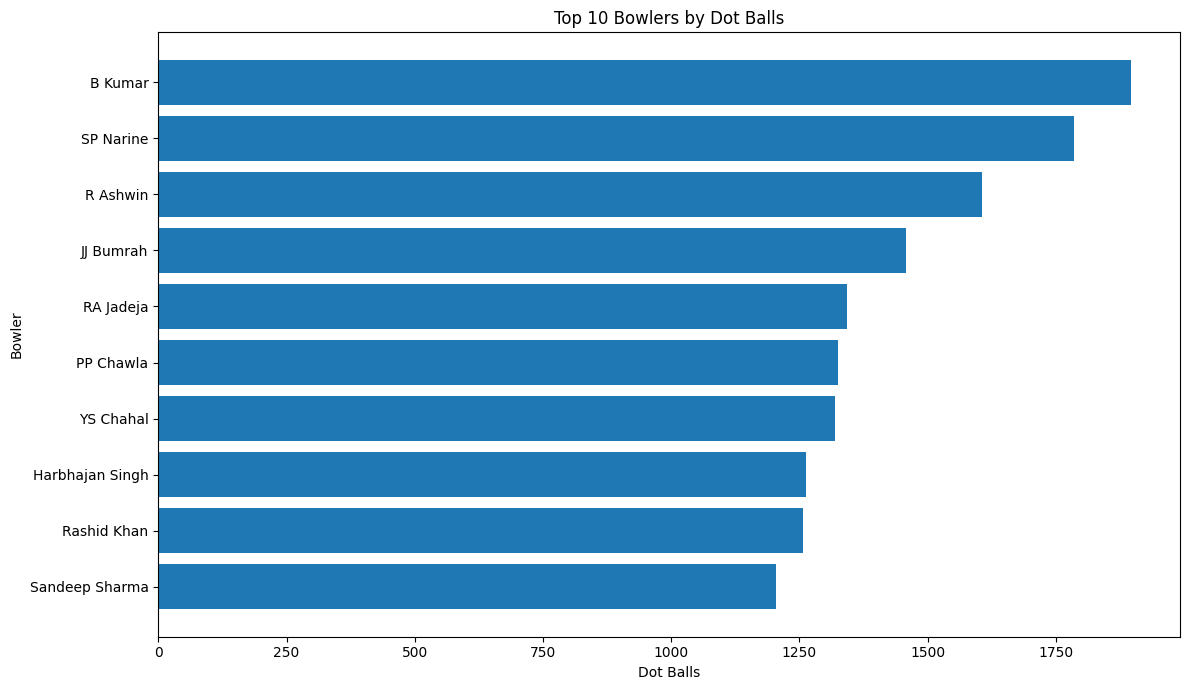

In [12]:
top_dot_bowlers = (
    bowler_summary.nlargest(10, "dot_balls")
    .sort_values("dot_balls")
)

plt.figure(figsize=(12, 7))
plt.barh(
    top_dot_bowlers["bowler"],
    top_dot_bowlers["dot_balls"]
)
plt.title("Top 10 Bowlers by Dot Balls")
plt.xlabel("Dot Balls")
plt.ylabel("Bowler")
plt.tight_layout()
plt.show()

In [13]:
innings_bowling = (
    valid_bowling.groupby(
        ["match_id", "innings", "season", "bowling_team", "bowler"],
        dropna=False
    )
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        dot_balls=("dot_ball", "sum")
    )
    .reset_index()
)

innings_wickets = (
    credited_wickets.groupby(
        ["match_id", "innings", "bowler"]
    )
    .size()
    .rename("wickets")
    .reset_index()
)

innings_bowling = innings_bowling.merge(
    innings_wickets,
    on=["match_id", "innings", "bowler"],
    how="left"
)

innings_bowling["wickets"] = (
    innings_bowling["wickets"].fillna(0).astype(int)
)

innings_bowling["overs_equivalent"] = (
    innings_bowling["legal_balls"] / 6
)

innings_bowling["economy"] = np.where(
    innings_bowling["legal_balls"] > 0,
    innings_bowling["runs_conceded"] * 6
    / innings_bowling["legal_balls"],
    np.nan
)

best_figures = (
    innings_bowling.sort_values(
        ["wickets", "runs_conceded"],
        ascending=[False, True]
    )
    .head(20)
    .reset_index(drop=True)
)

display(best_figures)

,match_id,innings,season,bowling_team,bowler,runs_conceded,legal_balls,dot_balls,wickets,overs_equivalent,economy
0,1178394,2,2019.0,Mumbai Indians,AS Joseph,12.0,22,14,6,3.666667,3.272727
1,336005,1,NaN,Rajasthan Royals,Sohail Tanvir,14.0,24,16,6,4.000000,3.500000
2,980979,1,2016.0,Rising Pune Supergiants,A Zampa,19.0,24,11,6,4.000000,4.750000
3,392182,2,2009.0,Royal Challengers Bangalore,A Kumble,5.0,19,13,5,3.166667,1.578947
4,1370351,2,2023.0,Mumbai Indians,Akash Madhwal,5.0,21,16,5,3.500000,1.428571
5,1304102,1,2022.0,Mumbai Indians,JJ Bumrah,10.0,24,18,5,4.000000,2.500000
6,1370352,2,2023.0,Gujarat Titans,MM Sharma,10.0,14,8,5,2.333333,4.285714
7,501229,2,2011.0,Deccan Chargers,I Sharma,12.0,18,12,5,3.000000,4.000000
8,501201,1,2011.0,Mumbai Indians,SL Malinga,13.0,22,16,5,3.666667,3.545455
9,1136585,1,2018.0,Kings XI Punjab,AS Rajpoot,14.0,24,16,5,4.000000,3.500000


In [14]:
season_bowling = (
    valid_bowling.groupby(["season", "bowler"], dropna=False)
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        matches=("match_id", "nunique"),
        dot_balls=("dot_ball", "sum")
    )
    .reset_index()
)

season_wickets = (
    credited_wickets.groupby(["season", "bowler"])
    .size()
    .rename("wickets")
    .reset_index()
)

season_bowling = season_bowling.merge(
    season_wickets,
    on=["season", "bowler"],
    how="left"
)

season_bowling["wickets"] = (
    season_bowling["wickets"].fillna(0).astype(int)
)

season_bowling["economy"] = np.where(
    season_bowling["legal_balls"] > 0,
    season_bowling["runs_conceded"] * 6
    / season_bowling["legal_balls"],
    np.nan
)

top_bowler_per_season = (
    season_bowling.sort_values(
        ["season", "wickets", "economy"],
        ascending=[True, False, True]
    )
    .groupby("season", dropna=False)
    .head(1)
    .sort_values("season")
)

display(top_bowler_per_season)

,season,bowler,runs_conceded,legal_balls,matches,dot_balls,wickets,economy
76,2009.0,RP Singh,417.0,358,16,169,23,6.988827
226,2011.0,SL Malinga,375.0,378,16,183,28,5.952381
316,2012.0,M Morkel,453.0,378,16,154,25,7.190476
408,2013.0,DJ Bravo,497.0,375,18,135,32,7.952000
559,2014.0,MM Sharma,452.0,323,16,118,23,8.396285
627,2015.0,DJ Bravo,426.0,314,16,88,26,8.140127
718,2016.0,B Kumar,490.0,396,17,156,23,7.424242
828,2017.0,B Kumar,369.0,314,14,117,26,7.050955
924,2018.0,AJ Tye,448.0,336,14,108,24,8.000000
1049,2019.0,Imran Tahir,431.0,386,17,146,26,6.699482


In [15]:
team_bowling = (
    valid_bowling.groupby(["bowling_team", "bowler"], dropna=False)
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        matches=("match_id", "nunique"),
        dot_balls=("dot_ball", "sum")
    )
    .reset_index()
)

team_wickets = (
    credited_wickets.groupby(["bowling_team", "bowler"])
    .size()
    .rename("wickets")
    .reset_index()
)

team_bowling = team_bowling.merge(
    team_wickets,
    on=["bowling_team", "bowler"],
    how="left"
)

team_bowling["wickets"] = (
    team_bowling["wickets"].fillna(0).astype(int)
)

team_bowling["economy"] = np.where(
    team_bowling["legal_balls"] > 0,
    team_bowling["runs_conceded"] * 6
    / team_bowling["legal_balls"],
    np.nan
)

team_bowling_totals = (
    team_bowling.groupby("bowling_team")
    .agg(
        runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_balls", "sum"),
        wickets=("wickets", "sum"),
        dot_balls=("dot_balls", "sum"),
        bowlers=("bowler", "nunique")
    )
    .reset_index()
    .sort_values("wickets", ascending=False)
)

team_bowling_totals["economy"] = np.where(
    team_bowling_totals["legal_balls"] > 0,
    team_bowling_totals["runs_conceded"] * 6
    / team_bowling_totals["legal_balls"],
    np.nan
)

display(team_bowling_totals)

,bowling_team,runs_conceded,legal_balls,wickets,dot_balls,bowlers,economy
10,Mumbai Indians,45789.0,33646,1640,12221,128,8.165428
0,Chennai Super Kings,41446.0,30663,1517,11098,93,8.109970
8,Kolkata Knight Riders,42927.0,31667,1494,11418,101,8.133451
13,Rajasthan Royals,40226.0,28847,1318,10070,120,8.366763
16,Royal Challengers Bangalore,37227.0,27277,1283,9829,107,8.188657
18,Sunrisers Hyderabad,34084.0,24322,1155,8583,87,8.408190
6,Kings XI Punjab,29883.0,21663,982,7686,84,8.276693
3,Delhi Daredevils,24212.0,18089,795,6521,76,8.030958
2,Delhi Capitals,20230.0,13906,684,4693,51,8.728606
5,Gujarat Titans,13224.0,8829,480,3163,34,8.986748


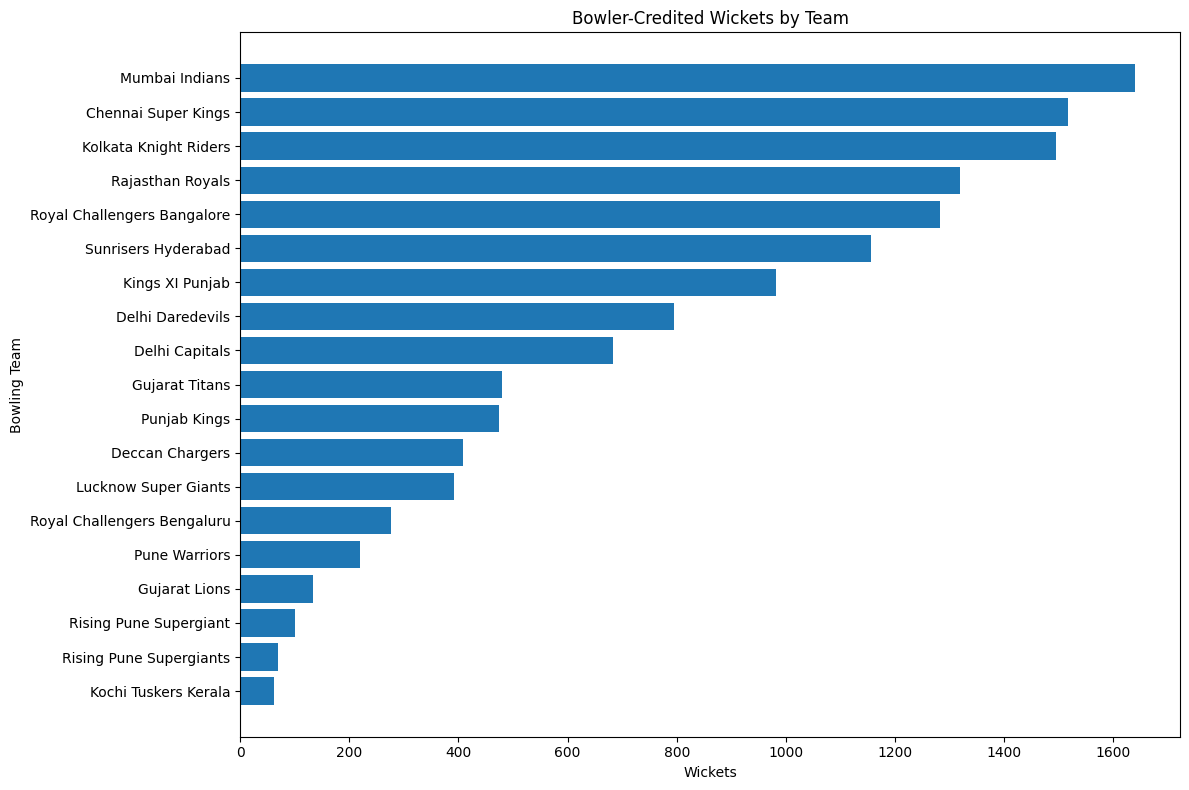

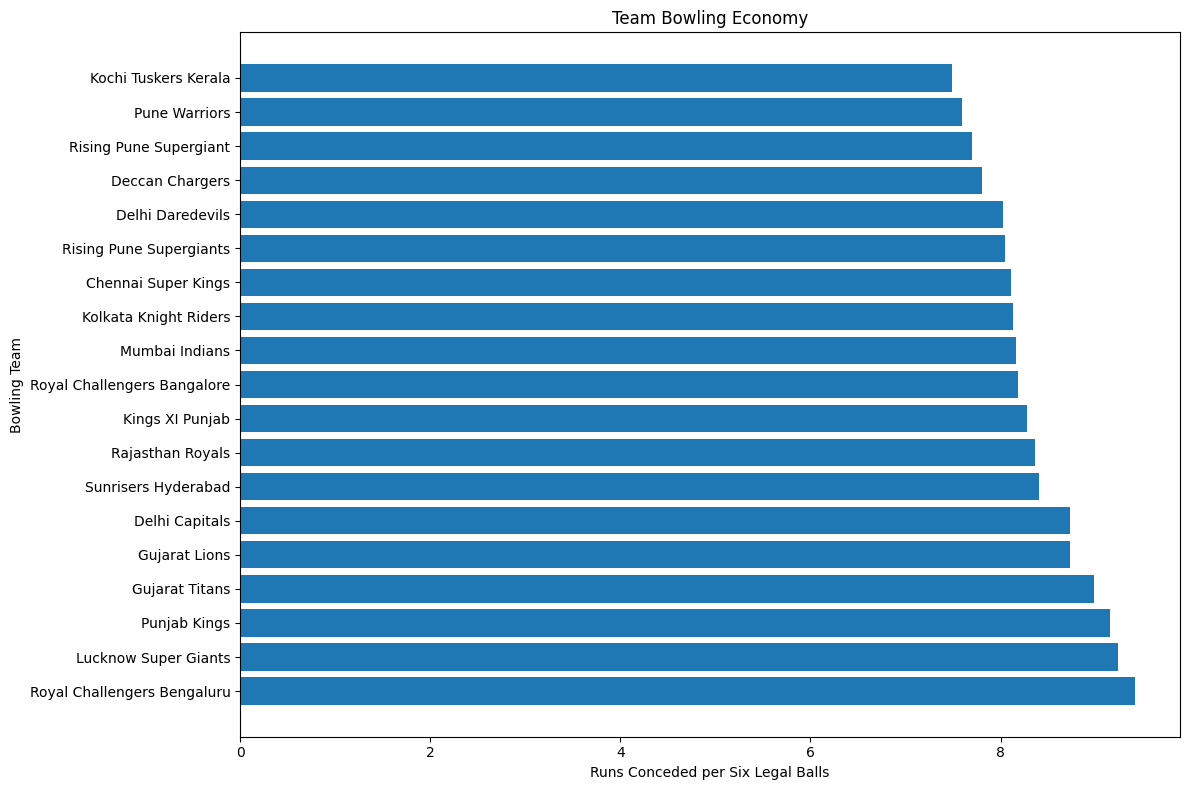

In [16]:
team_plot = team_bowling_totals.sort_values("wickets")

plt.figure(figsize=(12, 8))
plt.barh(
    team_plot["bowling_team"],
    team_plot["wickets"]
)
plt.title("Bowler-Credited Wickets by Team")
plt.xlabel("Wickets")
plt.ylabel("Bowling Team")
plt.tight_layout()
plt.show()

economy_plot = (
    team_bowling_totals.dropna(subset=["economy"])
    .sort_values("economy", ascending=False)
)

plt.figure(figsize=(12, 8))
plt.barh(
    economy_plot["bowling_team"],
    economy_plot["economy"]
)
plt.title("Team Bowling Economy")
plt.xlabel("Runs Conceded per Six Legal Balls")
plt.ylabel("Bowling Team")
plt.tight_layout()
plt.show()

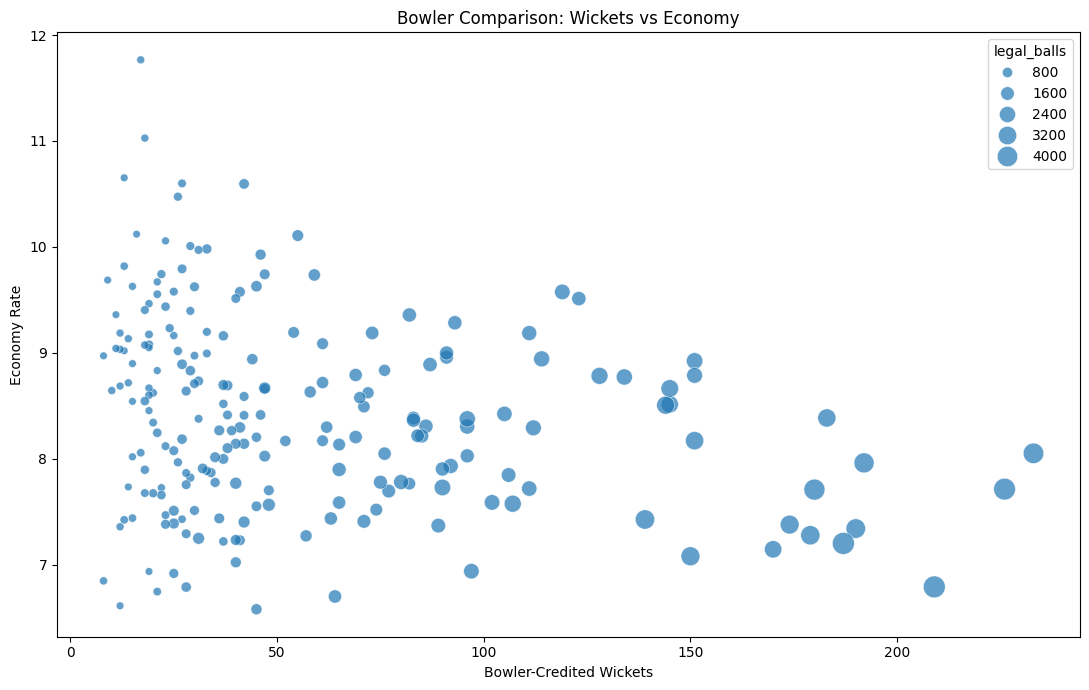

In [17]:
comparison_df = bowler_summary[
    (bowler_summary["legal_balls"] >= 300)
    & bowler_summary["economy"].notna()
].copy()

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=comparison_df,
    x="wickets",
    y="economy",
    size="legal_balls",
    sizes=(30, 250),
    alpha=0.7
)

plt.title("Bowler Comparison: Wickets vs Economy")
plt.xlabel("Bowler-Credited Wickets")
plt.ylabel("Economy Rate")
plt.tight_layout()
plt.show()

In [18]:
print("BOWLING ANALYSIS VALIDATION")
print("-" * 45)

print("Unique bowlers:", bowler_summary["bowler"].nunique())
print("Total legal balls:", int(bowler_summary["legal_balls"].sum()))
print("Total runs charged to bowlers:", int(bowler_summary["runs_conceded"].sum()))
print("Total bowler-credited wickets:", int(bowler_summary["wickets"].sum()))
print("Total dot balls:", int(bowler_summary["dot_balls"].sum()))
print("Total maidens:", int(bowler_summary["maidens"].sum()))

assert (bowler_summary["legal_balls"] >= 0).all()
assert (bowler_summary["runs_conceded"] >= 0).all()
assert (bowler_summary["wickets"] >= 0).all()
assert (bowler_summary["dot_balls"] >= 0).all()
assert (bowler_summary["maidens"] >= 0).all()

print("\nBasic validation checks passed.")

BOWLING ANALYSIS VALIDATION
---------------------------------------------
Unique bowlers: 578
Total legal balls: 284630
Total runs charged to bowlers: 394585
Total bowler-credited wickets: 13482
Total dot balls: 101230
Total maidens: 287

Basic validation checks passed.


In [19]:
bowler_summary.to_csv(
    OUTPUT_DIR / "bowler_career_statistics.csv",
    index=False
)

innings_bowling.to_csv(
    OUTPUT_DIR / "bowling_innings_statistics.csv",
    index=False
)

best_figures.to_csv(
    OUTPUT_DIR / "best_bowling_figures.csv",
    index=False
)

season_bowling.to_csv(
    OUTPUT_DIR / "season_bowling_statistics.csv",
    index=False
)

top_bowler_per_season.to_csv(
    OUTPUT_DIR / "top_bowler_per_season.csv",
    index=False
)

team_bowling.to_csv(
    OUTPUT_DIR / "team_bowler_statistics.csv",
    index=False
)

team_bowling_totals.to_csv(
    OUTPUT_DIR / "team_bowling_summary.csv",
    index=False
)

over_summary.to_csv(
    OUTPUT_DIR / "over_level_statistics.csv",
    index=False
)

print("Bowling analysis exports completed.")
print("Saved to:", OUTPUT_DIR)

for file_path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(file_path.name)

Bowling analysis exports completed.
Saved to: C:\Users\sitar\Downloads\ASSIGNMENT_CODE\INDIAN PREMIER LEAGUE\DATA\PROCESSED\BOWLING
best_bowling_figures.csv
bowler_career_statistics.csv
bowling_innings_statistics.csv
over_level_statistics.csv
season_bowling_statistics.csv
team_bowler_statistics.csv
team_bowling_summary.csv
top_bowler_per_season.csv


In [20]:
leaderboard_columns = [
    "bowler",
    "matches",
    "innings_bowled",
    "legal_balls",
    "runs_conceded",
    "wickets",
    "bowling_average",
    "economy",
    "bowling_strike_rate",
    "dot_balls",
    "maidens",
]

display(
    bowler_summary[leaderboard_columns]
    .sort_values(
        ["wickets", "economy"],
        ascending=[False, True]
    )
    .head(25)
    .round(2)
)

,bowler,matches,innings_bowled,legal_balls,runs_conceded,wickets,bowling_average,economy,bowling_strike_rate,dot_balls,maidens
0,YS Chahal,184,184,4037,5417.0,233,23.25,8.05,17.33,1319,4
1,B Kumar,206,206,4600,5913.0,226,26.16,7.71,20.35,1897,9
2,SP Narine,200,202,4660,5273.0,209,25.23,6.79,22.30,1786,3
3,PP Chawla,191,191,3850,5108.0,192,26.60,7.96,20.05,1325,1
4,JJ Bumrah,158,162,3653,4469.0,190,23.52,7.34,19.23,1458,6
5,R Ashwin,217,217,4710,5652.0,187,30.22,7.20,25.19,1606,4
6,DJ Bravo,158,158,3120,4360.0,183,23.83,8.38,17.05,998,3
7,RA Jadeja,237,237,4254,5465.0,180,30.36,7.71,23.63,1342,1
8,Rashid Khan,153,156,3543,4297.0,179,24.01,7.28,19.79,1257,3
9,A Mishra,162,162,3371,4145.0,174,23.82,7.38,19.37,1185,4
